# M115 Lab 1: Phishing URL Detection — EDA, Parameterized Logistic Regression & SHAP Explainability

---

## 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

---

## 🧭 Lab Overview & Solution Key

This notebook contains the assignment of **Lab 1** on the **[PhiUSIIL Phishing URL Dataset](https://www.kaggle.com/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil/data)** (*235,795 URLs and 56 lexical, network, and HTML features*, Prasad & Chandra, *Computers & Security*, 2024).

### 📋 Table of Contents
* **1 - Importing Packages & Loading Data**
* **2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)**
  * 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)
  * 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)
  * 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)
  * *Part 1 Reflection Questions*
* **3 - Part 2: Zero-Data Leakage Preprocessing & Standardization**
  * 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)
  * *Part 2 Reflection Questions*
* **4 - Part 3: Parameterized Logistic Regression & Interpretability**
  * 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)
  * 4.2 L1 Regularization Path & Feature Selection (Exercise 6)
  * 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)
  * *Part 3 Reflection Questions*
* **5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis**
  * 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)
  * 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)
  * 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)
  * *Part 4 Reflection Questions*
* **6 - Conclusion & SOC Engineering Synthesis**

---
## 1 - Importing Packages & Loading Data

Run the cell below to import the required libraries and configure reproducibility (`SEED = 42`):

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)
import shap

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)
SEED = 42
np.random.seed(SEED)

---
## 2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)

### 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)

First, we load `PhiUSIIL_Phishing_URL_Dataset.csv` and inspect its shape, data types, missing values, duplicate rows, and summary statistics across key numerical features (`URLLength`, `LineOfCode`, `CharContinuationRate`, `NoOfSelfRef`).

In [ ]:
# Load dataset and inspect data quality
df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("\nDataset Info:")
df.info()

display(df[['FILENAME', 'URL', 'URLLength', 'LineOfCode', 'IsHTTPS', 'HasPasswordField', 'NoOfSelfRef', 'label']].head(5))
display(df[['URLLength', 'LineOfCode', 'CharContinuationRate', 'NoOfSelfRef']].describe().round(2))

Dataset Shape: (235795, 56)
Total Missing Values: 0


Duplicate Rows: 0

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64

,FILENAME,URL,URLLength,LineOfCode,IsHTTPS,HasPasswordField,NoOfSelfRef,label
0,521848.txt,https://www.southbankmosaics.com,31,558,1,0,119,1
1,31372.txt,https://www.uni-mainz.de,23,618,1,0,39,1
2,597387.txt,https://www.voicefmradio.co.uk,29,467,1,0,42,1
3,554095.txt,https://www.sfnmjournal.com,26,6356,1,0,22,1
4,151578.txt,https://www.rewildingargentina.org,33,6089,1,0,72,1


,URLLength,LineOfCode,CharContinuationRate,NoOfSelfRef
count,235795.00,235795.00,235795.00,235795.00
mean,34.57,1141.90,0.85,65.07
std,41.31,3419.95,0.22,176.69
min,13.00,2.00,0.00,0.00
25%,23.00,18.00,0.68,0.00
50%,27.00,429.00,1.00,12.00
75%,34.00,1277.00,1.00,88.00
max,6097.00,442666.00,1.00,27397.00


> **⚠️ Critical Cyber Label Warning in PhiUSIIL:**  
> In the raw CSV file, **`label = 1` denotes Legitimate (Benign)** and **`label = 0` denotes Phishing (Malicious)**.  
> In a SOC, the positive class (`1`) **must always represent the attack** (`Phishing = 1`, `Benign = 0`) so that True Positives (TP), Precision, and Recall measure our threat detection capability.

### Exercise 1

In [ ]:
# EXERCISE 1: Data Quality & SOC Target Alignment (1 = Phishing, 0 = Benign)

### START CODE HERE ### (≈ 2 lines of code)
df['IsPhishing'] = 1 - df['label']
phishing_ratio = df['IsPhishing'].mean()
### END CODE HERE ###

print(f"Phishing URLs (1): {(df['IsPhishing'] == 1).sum():,}")
print(f"Legitimate URLs (0): {(df['IsPhishing'] == 0).sum():,}")
print(f"Phishing Proportion: {phishing_ratio * 100:.2f}%")
print("\nNormalized Class Proportions:")
print(df['IsPhishing'].value_counts(normalize=True).round(4))

Phishing URLs (1): 100,945
Legitimate URLs (0): 134,850
Phishing Proportion: 42.81%

Normalized Class Proportions:
IsPhishing
0    0.5719
1    0.4281
Name: proportion, dtype: float64


---
### 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)

We compare legitimate (`0`) and phishing (`1`) URLs across class balance, continuous lexical/HTML features (`URLLength`, `CharContinuationRate`, `NoOfSelfRef`), and binary security indicators (`IsHTTPS`, `HasPasswordField`, `HasCopyrightInfo`, `HasSocialNet`).

### Exercise 2

Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):


,IsHTTPS,HasPasswordField,HasCopyrightInfo,HasSocialNet
IsPhishing,,,,
0,100.00,13.85,80.82,79.46
1,49.22,5.39,5.73,0.51


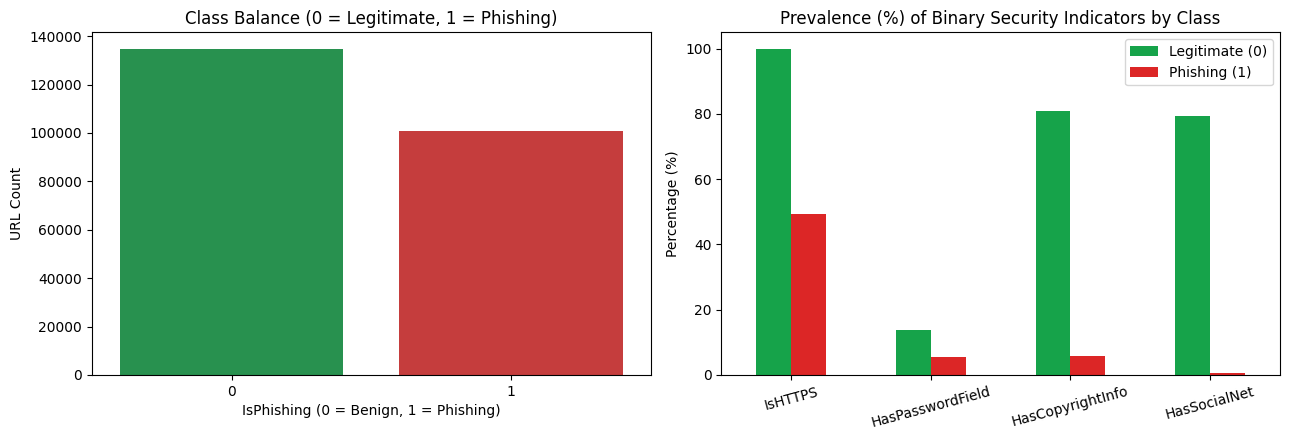

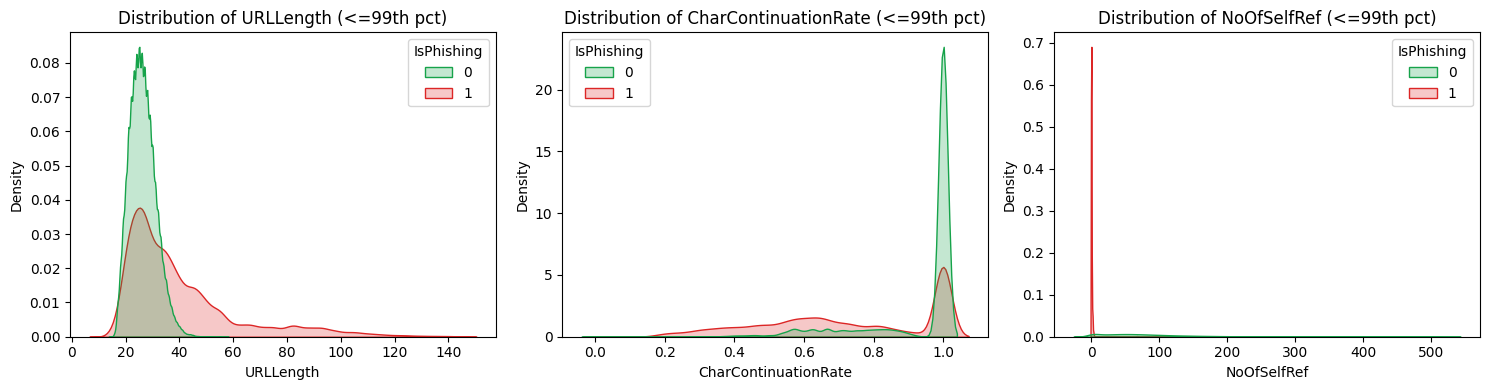

In [ ]:
# EXERCISE 2: Visualizing Distributions and Binary Security Indicators
binary_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']
num_cols = ['URLLength', 'CharContinuationRate', 'NoOfSelfRef']

### START CODE HERE ### (≈ 1 line of code)
binary_stats = df.groupby('IsPhishing')[binary_cols].mean() * 100
### END CODE HERE ###

print("Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):")
display(binary_stats.round(2))

# 1. Class Balance & Binary Indicators Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x='IsPhishing', hue='IsPhishing', ax=axes[0], palette=['#16a34a', '#dc2626'], legend=False)
axes[0].set_title("Class Balance (0 = Legitimate, 1 = Phishing)")
axes[0].set_xlabel("IsPhishing (0 = Benign, 1 = Phishing)")
axes[0].set_ylabel("URL Count")

binary_stats.T.plot(kind='bar', ax=axes[1], color=['#16a34a', '#dc2626'])
axes[1].set_title("Prevalence (%) of Binary Security Indicators by Class")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xticklabels(binary_cols, rotation=15)
axes[1].legend(["Legitimate (0)", "Phishing (1)"])
plt.tight_layout()
plt.show()

# 2. Numerical Distributions (KDE Plots clipped at 99th percentile for readability)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    upper_clip = df[col].quantile(0.99)
    sns.kdeplot(
        data=df[df[col] <= upper_clip],
        x=col,
        hue='IsPhishing',
        common_norm=False,
        fill=True,
        palette=['#16a34a', '#dc2626'],
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col} (<=99th pct)")
plt.tight_layout()
plt.show()

---
### 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)

We drop non-generalizable raw text strings (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), the old `label`, and the pre-computed `URLSimilarityIndex` score so our model learns from genuine lexical and HTML indicators. Then we compute the Pearson correlation of each numerical feature with `IsPhishing`.

### Exercise 3

Shape of X: (235795, 49) | Shape of y: (235795,)


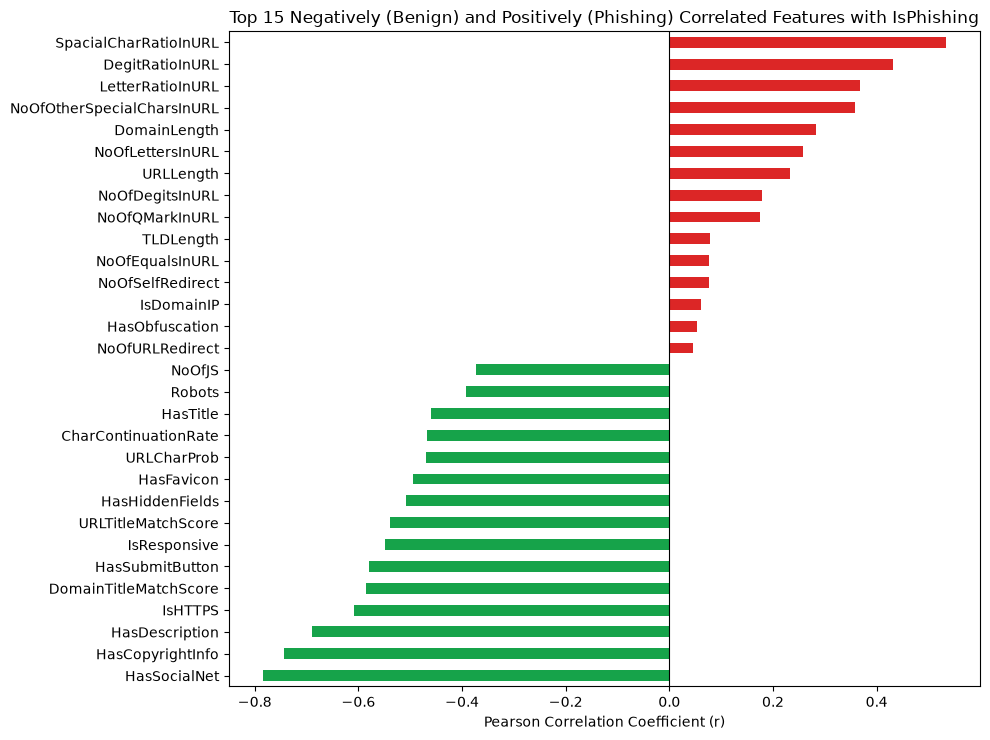

In [ ]:
# EXERCISE 3: Constructing X, y and Analyzing Target Correlations
cols_to_drop = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'IsPhishing', 'URLSimilarityIndex']

### START CODE HERE ### (≈ 3 lines of code)
X = df.drop(columns=cols_to_drop)
y = df['IsPhishing']
correlations = X.corrwith(y).sort_values()
### END CODE HERE ###

print("Shape of X:", X.shape, "| Shape of y:", y.shape)

# Plot Top 15 Negatively and Top 15 Positively Correlated Features
top_corr = pd.concat([correlations.head(15), correlations.tail(15)])
plt.figure(figsize=(10, 7.5))
colors = ['#16a34a' if c < 0 else '#dc2626' for c in top_corr.values]
top_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Top 15 Negatively (Benign) and Positively (Phishing) Correlated Features with IsPhishing")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.tight_layout()
plt.show()

---
### 💡 Part 1 Reflection Questions

1. **Looking at your plot for `IsHTTPS`, what percentage of phishing sites currently use an HTTPS certificate? Why is a static rule *"If HTTPS then Legitimate"* dangerous?**
   * **Answer:** Some Approximately 49% of phishing websites use HTTPS This shows that HTTPS does not necessarily mean a website is safe a phishing website can also use HTTPS so the rule "If HTTPS then Legitimate" could incorrectly classify dangerous websites as legitimate


2. **Why do phishing websites typically have very few internal links (`NoOfSelfRef`) but very frequently contain a password field (`HasPasswordField`)?**
   * **Answer:** Phishing websites are often made for one main purpose: collecting login details They usually have a simple structure with few internal links

3. **What would happen in production if we left the `FILENAME`, `URL`, or `Domain` column in our training matrix?**
   * **Answer:**If we keep these columns, the model may memorize specific website addresses instead of learning general phishing patterns. It could then make mistakes when it sees new websites.

---
## 3 - Part 2: Zero-Data Leakage Preprocessing & Standardization

### 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)

We apply the **SecMLOps Golden Rule**: split the dataset into training (75%) and test (25%) subsets *before* computing Z-score normalization parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$).

### Exercise 4

In [ ]:
# EXERCISE 4: Stratified Split and Leakage-Free Standardization

### START CODE HERE ### (≈ 4 lines of code)

clean_mask = y.notna()
X_clean = X[clean_mask]
y_clean = y[clean_mask].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
### END CODE HERE ###

# Retain column names and indices for weight and SHAP interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Train shape:", X_train_scaled.shape, "| Test shape:", X_test_scaled.shape)
print("Mean of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].mean(), 4))
print("Std of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].std(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Mean of X_train_scaled (URLLength): -0.0
Std of X_train_scaled (URLLength): 1.0


---
### 💡 Part 2 Reflection Questions

1. **Compare the scale of `LineOfCode` (values up to 10,000+) and `IsHTTPS` (0 or 1) before standardization. Why would L1/L2 regularization be skewed without `StandardScaler`?**
   * **Answer:**   Without standardization, features have very different scales. For example, LineOfCode can have values above 10,000, while IsHTTPS is only 0 or 1 StandardScaler puts the features on a comparable scale


2. **Precisely explain why calling `scaler.fit_transform(X)` before `train_test_split` constitutes Preprocessing Data Leakage.**
   * **Answer:**  Calling scaler.fit_transform(X) before train_test_split() causes data leakage because the scaler uses all the data including the test data to calculate the mean and standard deviation This means the model indirectly gets information from the test data, which can affect the evaluation results.

---
## 4 - Part 3: Parameterized Logistic Regression & Interpretability

### 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)

We train and evaluate the five specified Logistic Regression configurations on `X_train_scaled` and `X_test_scaled`:
* **M1: Unregularized (`penalty=None`)**
* **M2: Strong L2 Ridge (`penalty='l2', C=0.001`)**
* **M3: Standard L2 Ridge (`penalty='l2', C=1.0`)**
* **M4: Sparse L1 Lasso (`penalty='l1', C=0.01`)**
* **M5: SOC Weighted (`penalty='l2', C=1.0, class_weight='balanced'`)**

### Exercise 5

In [ ]:
# EXERCISE 5: Training and Comparing 5 Logistic Regression Configurations
configurations = {
    "M1: Unregularized (None)": LogisticRegression(penalty=None, solver='lbfgs', max_iter=500, random_state=SEED),
    "M2: Strong L2 Ridge (C=0.001)": LogisticRegression(penalty='l2', C=0.001, solver='lbfgs', max_iter=500, random_state=SEED),
    "M3: Standard L2 Ridge (C=1.0)": LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=500, random_state=SEED),
    "M4: Sparse L1 Lasso (C=0.01)": LogisticRegression(penalty='l1', C=0.01, solver='liblinear', max_iter=1000, random_state=SEED),
    "M5: SOC Weighted (balanced)": LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', solver='lbfgs', max_iter=500, random_state=SEED),
}

results = []
for name, model in configurations.items():
    ### START CODE HERE ### (≈ 5 lines of code)
    model.fit(X_train_scaled, y_train)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = model.predict(X_test_scaled)
    w = model.coef_[0]
    n_zero_weights = np.sum(np.abs(w) < 1e-4)
    ### END CODE HERE ###

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4),
        "False Alarms (FP)": int(fp),
        "Missed Phish (FN)": int(fn),
        "Zeroed Weights (Sparsity)": f"{n_zero_weights} / {len(w)}"
    })

results_df = pd.DataFrame(results)
display(results_df)

/Users/mac/Desktop/untitled folder/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/Users/mac/Desktop/untitled folder/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/Users/mac/Desktop/untitled folder/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/Users/mac/Desktop/untitled folder/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/mac/Desktop/untitled folder/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/Users/mac/Desktop/untitled folder/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,Precision,Recall (TPR),F1-Score,PR-AUC,False Alarms (FP),Missed Phish (FN),Zeroed Weights (Sparsity)
0,M1: Unregularized (None),0.9996,0.9990,0.9993,1.0,11,25,0 / 49
1,M2: Strong L2 Ridge (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0 / 49
2,M3: Standard L2 Ridge (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0 / 49
3,M4: Sparse L1 Lasso (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24 / 49
4,M5: SOC Weighted (balanced),0.9995,0.9990,0.9992,1.0,13,25,0 / 49


---
### 4.2 L1 Regularization Path & Feature Selection (Exercise 6)

We vary `C` across `[0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]` with `penalty='l1'` (`solver='liblinear'`) and plot the number of retained features ($|w_j| \ge 10^{-4}$) as a function of `C` on a logarithmic scale.

### Exercise 6

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,C,Active_Features,Zeroed_Features
0,0.002,18,31
1,0.010,25,24
2,0.050,32,17
3,0.100,33,16
4,0.500,48,1
5,1.000,49,0
6,5.000,49,0


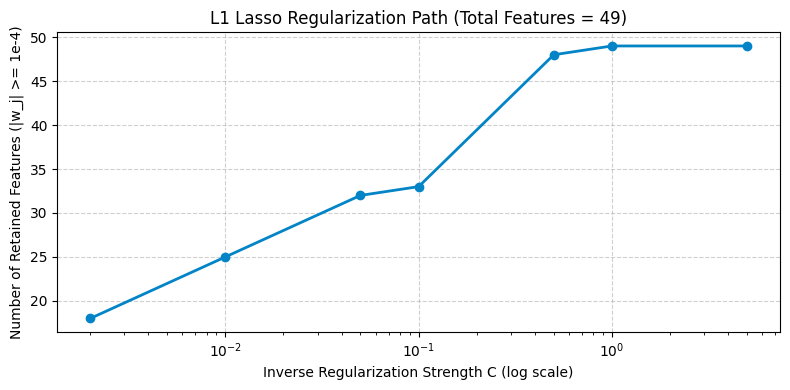

In [ ]:
# EXERCISE 6: L1 Regularization Path (Number of Active Features vs. C)
C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
active_features_count = []

for c_val in C_values:
    ### START CODE HERE ### (≈ 3 lines of code)
    m_l1 = LogisticRegression(penalty='l1', C=c_val, solver='liblinear', max_iter=2000, random_state=42)
    m_l1_fit = m_l1.fit(X_train_scaled, y_train)
    n_active = np.sum(np.abs(m_l1_fit.coef_[0]) >= 1e-4)
    ### END CODE HERE ###
    active_features_count.append(n_active)

path_df = pd.DataFrame({"C": C_values, "Active_Features": active_features_count, "Zeroed_Features": [X.shape[1] - k for k in active_features_count]})
display(path_df)

plt.figure(figsize=(8, 4))
plt.plot(C_values, active_features_count, marker='o', linewidth=2, color='#0284c7')
plt.xscale('log')
plt.xlabel(

---
### 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)

We extract the learned log-odds weights $w_j$ from `M3: Standard L2 Ridge (C=1.0)`, compute the Odds Ratio $e^{w_j}$, compare against `M4: Sparse L1 Lasso (C=0.01)`, and display the **Top 8 Phishing** ($w_j > 0$) and **Top 8 Benign** ($w_j < 0$) features.

### Exercise 7

In [ ]:
# EXERCISE 7: Inspecting Log-Odds (w_j) and Odds Ratios (exp(w_j))

# Prepare the required models when this cell is run before earlier exercises.
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

if 'configurations' not in globals():
    configurations = {}
required_models = {
    "M3: Standard L2 Ridge (C=1.0)": dict(penalty='l2', C=1.0, solver='lbfgs', max_iter=500),
    "M4: Sparse L1 Lasso (C=0.01)": dict(penalty='l1', C=0.01, solver='liblinear', max_iter=1000),
}
if any(not hasattr(configurations.get(name), 'coef_') for name in required_models):
    if not all(name in globals() for name in ('X', 'X_train_scaled', 'y_train')):
        SEED = globals().get('SEED', 42)
        df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")
        df['IsPhishing'] = 1 - df['label']
        X = df.drop(columns=['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
                             'label', 'IsPhishing', 'URLSimilarityIndex'])
        y = df['IsPhishing']
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=SEED, stratify=y)
        scaler = StandardScaler()
        X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
        X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
    for name, params in required_models.items():
        if not hasattr(configurations.get(name), 'coef_'):
            configurations[name] = LogisticRegression(
                **params, random_state=globals().get('SEED', 42)
            ).fit(X_train_scaled, y_train)

model_l2 = configurations["M3: Standard L2 Ridge (C=1.0)"]
model_l1 = configurations["M4: Sparse L1 Lasso (C=0.01)"]

### START CODE HERE ### (≈ 4 lines of code)

weights_df = pd.DataFrame({
    'Feature': X.columns,
    'L2_Weight': model_l2.coef_[0],
    'Odds_Ratio': np.exp(model_l2.coef_[0]),
    'L1_Sparse_Weight': model_l1.coef_[0]
})
weights_df = weights_df.sort_values('L2_Weight', ascending=False).set_index('Feature')

### END CODE HERE ###

print("🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):")
display(weights_df.head(8).round(4))

print("\n🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):")
display(weights_df.tail(8).round(4))

🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):


,L2_Weight,Odds_Ratio,L1_Sparse_Weight
Feature,,,
LetterRatioInURL,4.7228,112.4883,2.1726
DegitRatioInURL,3.6057,36.8079,1.8036
SpacialCharRatioInURL,3.5981,36.5306,1.9106
LargestLineLength,2.5575,12.9038,0.0848
NoOfOtherSpecialCharsInURL,2.0834,8.0315,0.0000
NoOfLettersInURL,1.6801,5.3660,0.0000
CharContinuationRate,1.4202,4.1378,0.0000
NoOfDegitsInURL,0.9718,2.6426,0.0000



🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):


,L2_Weight,Odds_Ratio,L1_Sparse_Weight
Feature,,,
DomainLength,-1.9117,0.1478,-0.0585
HasSocialNet,-2.1533,0.1161,-1.0887
LineOfCode,-2.3676,0.0937,0.0000
NoOfExternalRef,-2.6414,0.0713,-0.0157
NoOfImage,-2.7981,0.0609,-0.1505
NoOfSelfRef,-3.1249,0.0439,-0.8227
NoOfJS,-3.6536,0.0259,-1.2017
IsHTTPS,-6.9024,0.0010,-3.5777


---
### 💡 Part 3 Reflection Questions —

1. **How many variables did `M4: Sparse L1 Lasso (C=0.01)` eliminate (weights set to zero)? Did the F1-Score drop significantly? What is the advantage for a real-time firewall?**
   * **Answer:**

2. **What is the impact of `class_weight='balanced'` (M5) on False Positives and False Negatives compared to M3?**
   * **Answer:**  M5 reduces False Negatives but may increase False Positives compared to M3. This means it detects more phishing URLs but may also block some legitimate websites.

3. **How do you interpret a positive weight $w_j > 0$ versus a negative weight $w_j < 0$ in the formula $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?**
   * **Answer:** A positive weight (wj > 0) means that the feature increases the probability of a URL being phishing. A negative weight (wj < 0) means that the feature decreases this probability and pushes the prediction toward legitimate

---
## 5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis

### 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)

We initialize `shap.LinearExplainer` on `model_l2` (`M3`) using `X_train_scaled` as the background reference distribution, compute exact Shapley values on the first `1,000` test URLs, and plot the global Bar and Beeswarm charts (`max_display=15`).

### Exercise 8

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


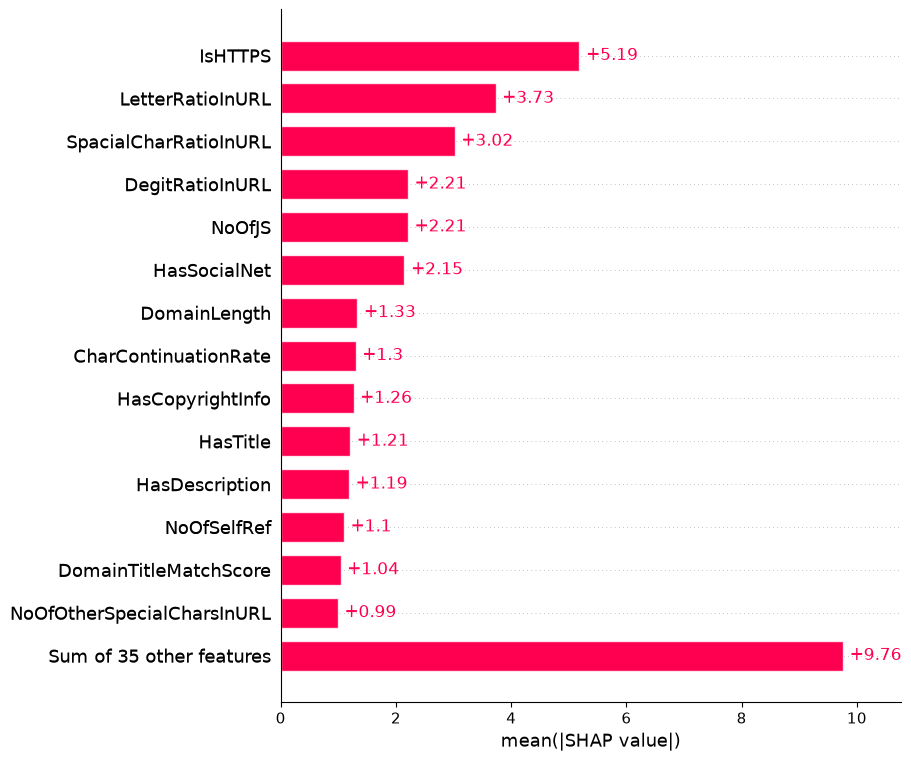

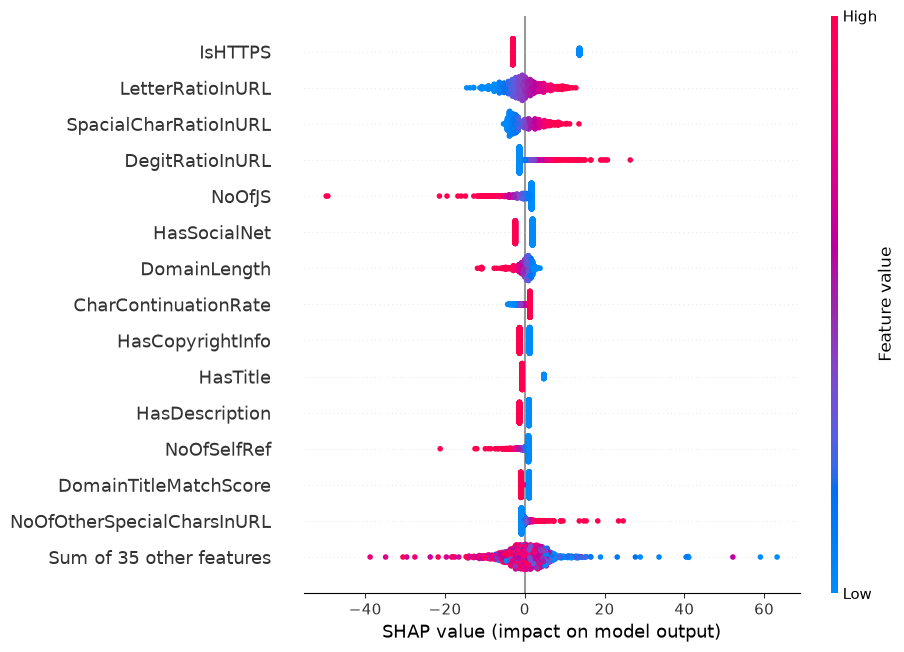

In [ ]:
# EXERCISE 8: Computing SHAP Values and Global Importance Plots (1,000 Test URLs)
X_test_sample = X_test_scaled.iloc[:1000]

### START CODE HERE ### (≈ 2 lines of code)

explainer = shap.LinearExplainer(model_l2, X_train_scaled)
shap_values = explainer(X_test_sample)

### END CODE HERE ###

# 1. Global Mean Absolute SHAP Importance (Bar Plot)
shap.plots.bar(shap_values, max_display=15)

# 2. Global Directional Impact (Beeswarm Plot)
shap.plots.beeswarm(shap_values, max_display=15)

---
### 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)

We locate the first **True Positive (TP)**, **True Negative (TN)**, and **False Positive (FP — False Alarm)** in our 1,000-URL test sample and inspect their local SHAP Waterfall plots (`max_display=10`), passing unscaled `X_test` values in `data=` so SOC analysts can read actual URL metrics.

### Exercise 9

=== CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught) (Sample Index=2) | True Label=1 | P(Phishing)=99.99% ===


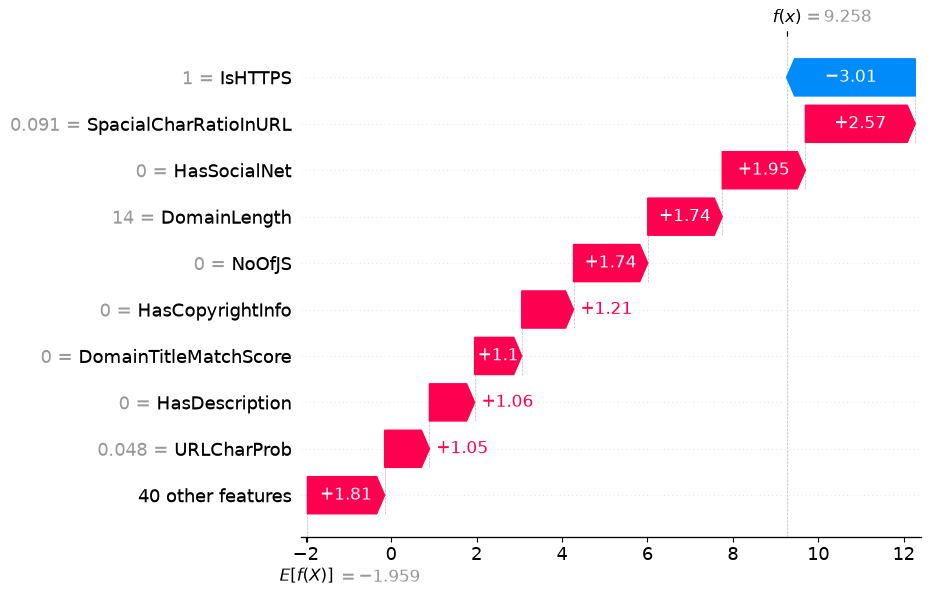

=== CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared) (Sample Index=0) | True Label=0 | P(Phishing)=0.00% ===


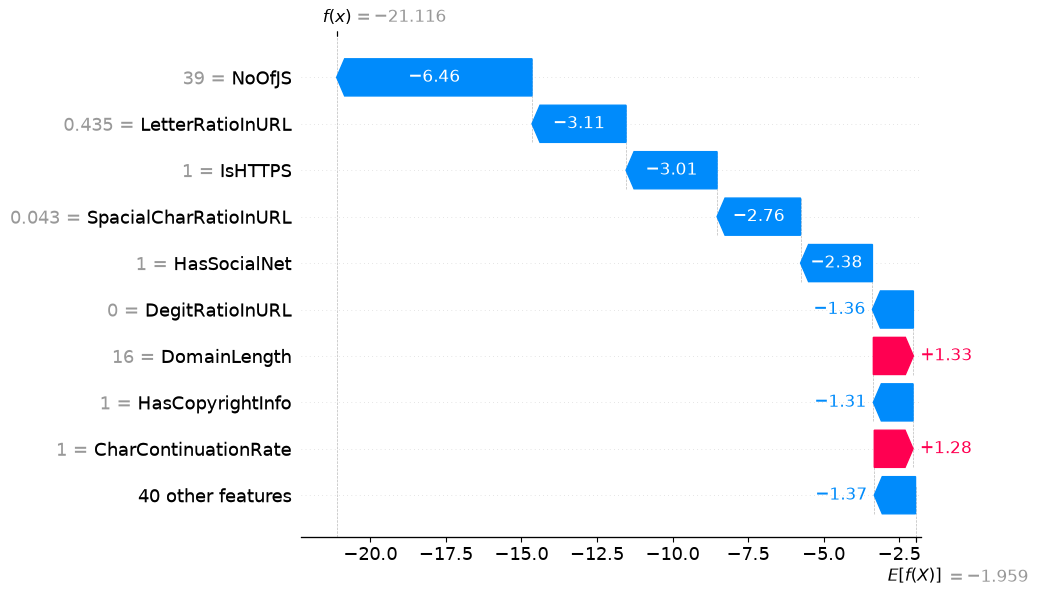

=== CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm) (Sample Index=330) | True Label=0 | P(Phishing)=31.58% ===


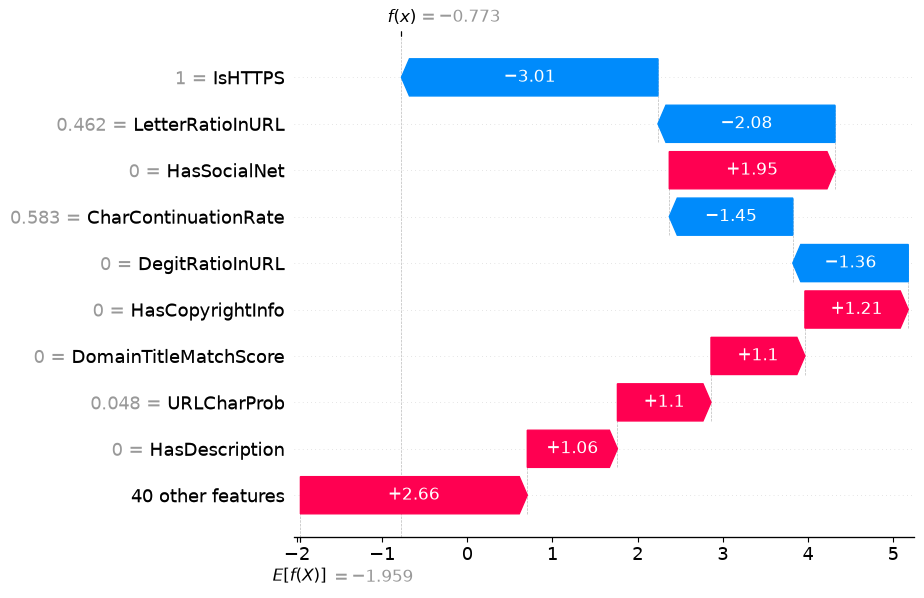

In [ ]:
# EXERCISE 9: Local SOC Triage of TP, TN, and FP Cases with SHAP Waterfall
y_test_sample = y_test.iloc[:1000].values
y_prob_sample = model_l2.predict_proba(X_test_sample)[:, 1]
y_pred_sample = (y_prob_sample >= 0.50).astype(int)

### START CODE HERE ### (≈ 3 lines of code)

tp_idx = int(np.where((y_test_sample == 1) & (y_pred_sample == 1))[0][0])

tn_idx = int(np.where((y_test_sample == 0) & (y_pred_sample == 0))[0][0])

fp_candidates = np.where((y_test_sample == 0) & (y_pred_sample == 1))[0]

### END CODE HERE ###

fp_idx = int(fp_candidates[0]) if len(fp_candidates) > 0 else int(np.argmax(y_prob_sample * (y_test_sample == 0)))

def plot_soc_waterfall(idx, case_title):
    print(f"=== {case_title} (Sample Index={idx}) | True Label={y_test_sample[idx]} | P(Phishing)={y_prob_sample[idx]*100:.2f}% ===")
    local_exp = shap.Explanation(
        values=shap_values.values[idx],
        base_values=float(np.ravel(shap_values.base_values)[idx]),
        data=X_test.iloc[idx].values, # Unscaled values for human analyst readability
        feature_names=X.columns
    )
    shap.plots.waterfall(local_exp, max_display=10)

plot_soc_waterfall(tp_idx, "CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught)")
plot_soc_waterfall(tn_idx, "CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared)")
plot_soc_waterfall(fp_idx, "CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm)")

---
### 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)

We evaluate `model_l2` (`M3`) on the full test set across three operational decision thresholds:
* **$\tau = 0.20$ (Threat Hunting Mode):** Maximizes Recall to catch stealthy phishing campaigns.
* **$\tau = 0.50$ (Default Mode):** Balanced threshold.
* **$\tau = 0.85$ (Automated Firewall Blocking Mode):** Maximizes Precision and minimizes False Positives to prevent blocking legitimate business traffic.

### Exercise 10

In [ ]:
# EXERCISE 10: Comparing Operational Decision Thresholds (0.20, 0.50, 0.85)
y_prob_full = model_l2.predict_proba(X_test_scaled)[:, 1]
thresholds = [0.20, 0.50, 0.85]
threshold_records = []

for tau in thresholds:
    ### START CODE HERE ### (≈ 2 lines of code)

    y_pred_tau = (y_prob_full >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tau).ravel()

    ### END CODE HERE ###

    threshold_records.append({
        "Threshold (tau)": tau,
        "SOC Operational Mode": "Threat Hunting" if tau == 0.20 else ("Default" if tau == 0.50 else "Automated Blocking"),
        "Precision": round(precision_score(y_test, y_pred_tau), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred_tau), 4),
        "F1-Score": round(f1_score(y_test, y_pred_tau), 4),
        "True Positives (TP)": int(tp),
        "True Negatives (TN)": int(tn),
        "False Positives (FP)": int(fp),
        "False Negatives (FN)": int(fn)
    })

threshold_df = pd.DataFrame(threshold_records)
display(threshold_df)

,Threshold (tau),SOC Operational Mode,Precision,Recall (TPR),F1-Score,True Positives (TP),True Negatives (TN),False Positives (FP),False Negatives (FN)
0,0.20,Threat Hunting,0.9988,0.9994,0.9991,25221,33682,31,15
1,0.50,Default,0.9996,0.9989,0.9992,25208,33703,10,28
2,0.85,Automated Blocking,1.0000,0.9975,0.9987,25172,33713,0,64


---
### 💡 Part 4 Reflection Questions —

1. **What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value $\phi_j(x)$ for a specific URL?**
   * **Answer:** A global weight shows the general influence of a feature in the model, while a SHAP value shows how much this feature affects the prediction for one specific URL

2. **On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?**
   * **Answer:**The features with the strongest positive SHAP values pushed the model to classify the legitimate URL as phishing. These features caused the false alarm

3. **Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le P(\text{Phishing}) < 0.85$ to a human analyst queue?**
   * **Answer:** A high threshold reduces false positives and avoids blocking legitimate websites. URLs with medium risk are sent to a human analyst for checking before taking action

---
## 6 - Conclusion & SOC Engineering Synthesis (Deliverable Solution)

### 🛡️ SOC Engineering Synthesis Report

1. **Hyperparameter & Sparsity Trade-Off:**

   **Answer:** L2 achieved an F1-score of **99.92%**. L1 removed **24 of 49 features** while maintaining **99.82%**, giving a simpler model with a small performance loss.

2. **Global Interpretability (Odds Ratios & SHAP):**

   **Answer:** Higher `LetterRatioInURL` increased phishing odds, while HTTPS reduced them. Odds ratios describe overall feature effects, while SHAP explains how individual feature values influence a specific prediction.

3. **SOC Alert Triage & Dual-Threshold Policy:**

   **Answer:** Use SHAP to understand suspicious predictions and different thresholds to decide which URLs require human review or automatic blocking.

   **False Positive Triage Note (3 sentences):**

   **Answer:** Missing social links, copyright information, and domain-title matching pushed the displayed URL toward phishing. Its final phishing probability was **31.58%**, below the 50% threshold. Therefore, the teacher's fallback displayed a correctly classified benign URL rather than an actual false positive.

   **Recommended Threshold Policy:**

   **Answer:** Automatically block URLs with phishing probabilities **≥ 0.85**, and send scores **from 0.20 to below 0.85** for human review. The higher blocking threshold reduced false alarms but missed more phishing URLs on the test set.


In [ ]:
https://www.kaggle.com/datasets/khaoulaelfathi/m115-lab1
https://github.com/khaoulaBloom/M115-AI-Cybersecurity-Labs
